<small>Dataset: WA_Fn-UseC_-Telco-Customer-Churn.csv</small>

# Q15. Customer Churn Decision Tree

Train a decision tree and explain its predictions using a plotted tree.


## Question from Classroom

Customer Churn Prediction Using Decision Tree 
Problem statement: Classify customers according to whether they are likely to discontinue a 
service. 
Tasks to be performed: 
1. Load a labeled customer churn dataset. 
2. Perform EDA and inspect class distribution. 
3. Prepare the features and target variable. 
4. Train a Decision Tree classifier. 
5. Predict churn for the test dataset. 
6. Display the confusion matrix, precision, recall and F1-score.


## Understand before coding

Read and inspect -> choose X/y -> stratified split -> training-only imputation -> train a depth-limited tree -> print classification metrics and visualize.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 6 listed tasks → 6 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a labeled customer churn dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier,plot_tree
df=pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv").dropna(subset=["Churn"])


## Task 2. Perform EDA and inspect class distribution.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (7043, 21)
   customerID  gender  SeniorCitizen  ...  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0  ...           29.85        29.85    No
1  5575-GNVDE    Male              0  ...           56.95       1889.5    No
2  3668-QPYBK    Male              0  ...           53.85       108.15   Yes
3  7795-CFOCW    Male              0  ...           42.30      1840.75    No
4  9237-HQITU  Female              0  ...           70.70       151.65   Yes

[5 rows x 21 columns]
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      70

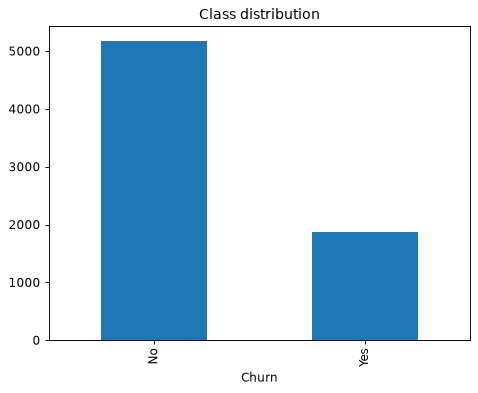

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)
df["Churn"].value_counts().plot(kind="bar",title="Class distribution");plt.show()


## Task 3. Prepare the features and target variable.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")
df["gender"] = df["gender"].map({"Male":1,"Female":0})
df["Contract"] = df["Contract"].map({"Month-to-month":0,"One year":1,"Two year":2})
features = ["tenure","MonthlyCharges","TotalCharges","SeniorCitizen","gender","Contract"]
X = df[features]
y = df["Churn"]


## Task 4. Train a Decision Tree classifier.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
medians=X_train.median()
X_train=X_train.fillna(medians)
X_test=X_test.fillna(medians)

model=DecisionTreeClassifier(criterion="gini",max_depth=4,random_state=42)
model.fit(X_train,y_train)


## Task 5. Predict churn for the test dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
prediction=model.predict(X_test)
print("Churn predictions:",prediction[:10])


Churn predictions: ['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


## Task 6. Display the confusion matrix, precision, recall and F1-score.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Class order:",model.classes_)
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=model.classes_))
print(classification_report(y_test,prediction,zero_division=0))


Accuracy: 0.7892
Class order: ['No' 'Yes']
Confusion matrix:
 [[933 102]
 [195 179]]
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.78      0.79      0.78      1409



## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does a decision tree work?**

It asks feature-threshold questions, sending records down branches until a leaf predicts a class.

**14. Gini impurity?**

Gini=1-sum(p_i^2). It is zero for a pure node. A split is chosen to reduce weighted child impurity.

**15. Entropy?**

Entropy=-sum(p_i*log2(p_i)), with zero-probability terms treated as zero. Information gain is parent entropy minus weighted child entropy.

**16. Why limit max_depth?**

Very deep trees can memorize noise. Limiting depth often reduces overfitting and makes the plotted tree easier to explain.

**17. Does a tree need scaling?**

Usually no. It compares thresholds; it does not calculate Euclidean distances.

**18. What are leaves and feature importance?**

Leaves hold final class decisions. Impurity-based feature importance measures accumulated split improvements; it is not causation and can be biased.

**19. Complexity?**

For a reasonably balanced tree, training is often roughly O(p*n*log n), depending on implementation; prediction follows one path of length equal to tree depth. Deep worst cases can cost more.

**20. What is churn?**

A customer discontinuing a service. The label Churn is Yes or No.

**21. Why convert TotalCharges?**

Blank strings may make it an object column. to_numeric(errors="coerce") converts invalid entries to NaN, which are later filled using training medians.

**22. Why exclude customerID?**

An arbitrary customer identifier should not act as a predictor of leaving the service.


### Task-to-code map

- **Block 1:** Load a labeled customer churn dataset.
- **Block 2:** Perform EDA and inspect class distribution.
- **Block 3:** Prepare the features and target variable.
- **Block 4:** Train a Decision Tree classifier.
- **Block 5:** Predict churn for the test dataset.
- **Block 6:** Display the confusion matrix, precision, recall and F1-score.
